In [2]:
from pylab import *

import skimage as ski
from skimage import color
from skimage import exposure
from skimage import filters
from skimage import io
from skimage import util
from scipy import ndimage

import imageio

import matplotlib.pyplot as plt
import numpy as np
import os

from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

import numpy as np

In [3]:
data_dir = ('sekvence//')


PRVI ZADATAK

Za resavanje prvog zadatka neophodno je da ucitanu sliku prebacimo u neki kolor sistem koji je pogodan za segmentaciju, i iz kog mozemo da izvucemo informaciju o boji. Istrazivanjem po internetu sam shvatio da su Ycbcr i HSV kolor sistemi najpogodniji za segmentaciju boje. Izabrao sam zato HSV, tako da sam sve ulazne slike iz RGB prebacivao u HSV. Informaciju o boji nam nosi H kanal, ali ogranicavanjem i ostalih kanala moze da se napravi bolja maska i da se uspesnije odradi segmentacija boje. Samo cistim namestanjem granica za H(hue), moze da se podesi dovoljno dobra maska koja obuhvata samo odredjene boje od znacaja. Sve ostale piksele postavljamo na crno. Pragovi za Hue komponentu su određeni eksperimentalno. Smanjenjem donje granice dolazi do uključivanja pozadine slične boje, dok povećanje gornje granice dovodi do gubitka delova tramvaja. Odabrani opseg predstavlja kompromis između kompletnosti segmentacije i minimizacije pojavljivanja 'laznih piksela' ili suma. U odabiranje maske sam ukljucio i informaciju o intenzitetu boje(S) i osvetljenosti(V) radi mozda malo boljih rezultata, iako mislim da moze da se napravi dovoljno dobra maska i beza toga. Za resavanje ovog zadatka koristio sam colorPicker (https://imagecolorpicker.com/) gde sam mogao da importujem ulaznu sliku i da pogledam vrednosti piksela, sto mi je pomoglo da znam u kom opsegu vrednosti se nalaze pikseli kako bih napravio sto bolju masku. Isto tako kada sam menjao sve tri slike da budu iste boje, odredio sam u colorPickeru jednu boju cije sam vrednosti definisao u kodu, pa su tako svi autobusi/tramvaji na sve tri slike identicne boje.  


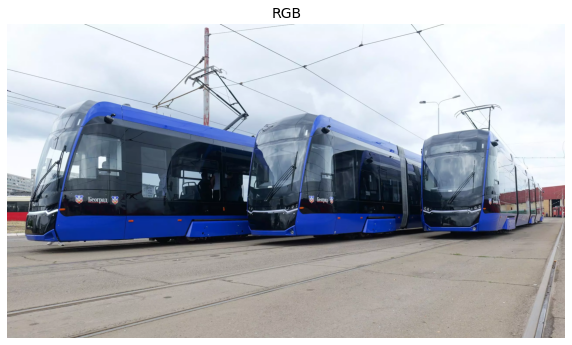

/home/lenovo/Marko/oe3dos/venv/lib/python3.9/site-packages/skimage/io/_plugins/matplotlib_plugin.py:158: UserWarning: Low image data range; displaying image with stretched contrast.
  lo, hi, cmap = _get_display_range(image)


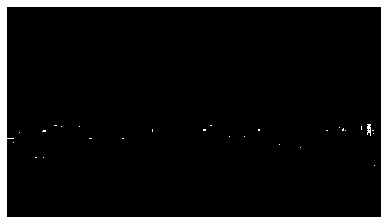

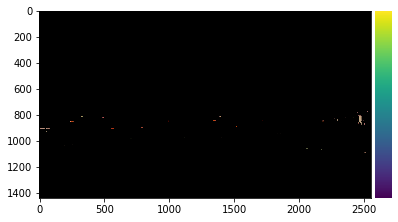

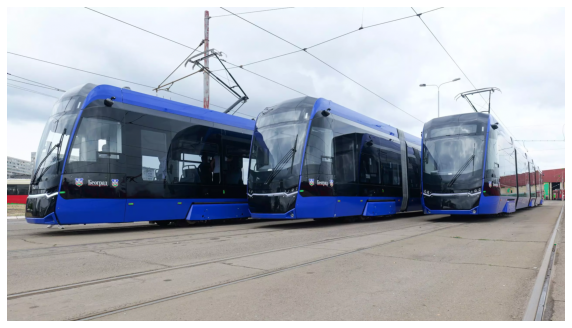

In [4]:
#Ucitavanje slike
img_gsp1 = ski.io.imread(data_dir + "gsp1.jpg")

#Prikaz RGB slike 
plt.figure(figsize=(10,10))
plt.imshow(img_gsp1)
plt.axis('off')
plt.title("RGB", fontsize=14)
plt.show()

#Prebacivanje slike iz RGB kolor sistema u HSV kolor sistem
img_hsv1 = ski.color.rgb2hsv(img_gsp1)


#-------------------------------------

#Pravljenje maske koja ce obuhvatiti plave tramvaje sa slike
mask1 = (img_hsv1[:,:,0] < 0.3) & (img_hsv1[:,:,1] > 0.3) 

ski.io.imshow(mask1, cmap = 'gray')
plt.axis('off')

img_masked1 = img_gsp1.copy()

#Kreirana maska se prosiruje na sve tri ravni kako bi se maskirala slika u boji
rgb_mask1 = np.stack((mask1, mask1, mask1), -1)

#Delovi koji nisu detektovani kao crvene oblasti se postavljaju na 0
img_masked1[~rgb_mask1] = 0

plt.figure();
ski.io.imshow(img_masked1);
plt.axis('off')

#-----------------------------------

#Promena H komponente boje 

img_hsv_out1 = img_hsv1.copy()
img_hsv_out1[:,:,0][mask1] += 0.355
img_hsv_out1[:,:,1][mask1] = 0.76

#Vracanje slike iz HSV kolor sistema u RGB i prikaz rezultata 
img_rgb_out1 = ski.color.hsv2rgb(img_hsv_out1)

plt.figure(figsize=(10, 10))
plt.imshow(img_rgb_out1)
plt.axis('off')

#Cuvanje izlazne slike u fajl
ski.io.imsave('gsp1Chagned.png', ski.util.img_as_ubyte(img_rgb_out1))



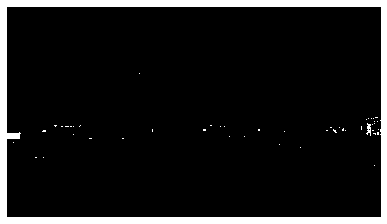

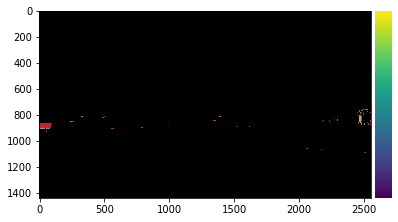

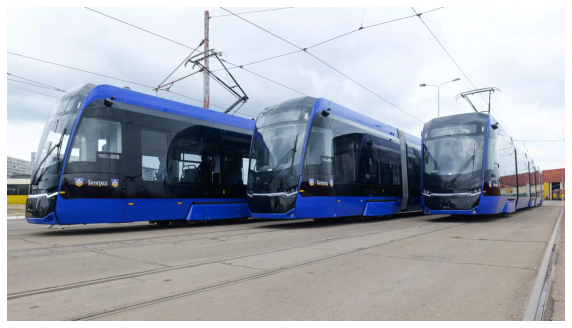

In [21]:
#Pravljenje maske koja obuhvata i crvene tramvaje/autobuse koju and-ujemo sa maskom za plave tramvaje 
#Time dobijamo celokupnu masku koja se trazi u zadatku
mask1_1 = mask1 | (img_hsv1[:,:,0] > 0.92) & (img_hsv1[:,:,1] > 0.44) 

ski.io.imshow(mask1_1, cmap = 'gray')
plt.axis('off')

img_masked1_1 = img_gsp1.copy()

#Kreirana maska se prosiruje na sve tri ravni kako bi se maskirala slika u boji
rgb_mask1_1 = np.stack((mask1_1, mask1_1, mask1_1), -1)

#Delovi koji nisu detektovani kao crvene oblasti se postavljaju na 0
img_masked1_1[~rgb_mask1_1] = 0

plt.figure();
ski.io.imshow(img_masked1_1);
plt.axis('off')

#Promena H i V komponente boje i zakucavanje vrednosti H i S na 0.14 i 0.9, sto cu koristiti i u ostale dve slike

img_hsv_out1_1 = img_hsv1.copy()
img_hsv_out1_1[:,:,0][mask1_1] = 0.14
img_hsv_out1_1[:,:,1][mask1_1] = 0.9

#Vracanje slike iz HSV kolor sistema u RGB i prikaz rezultata 
img_rgb_out1_1 = ski.color.hsv2rgb(img_hsv_out1_1)
plt.figure(figsize=(10, 10))
plt.imshow(img_rgb_out1_1)
plt.axis('off')

#Cuvanje izlazne slike u fajl
ski.io.imsave('gsp1_1Chagned.png', ski.util.img_as_ubyte(img_rgb_out1_1))


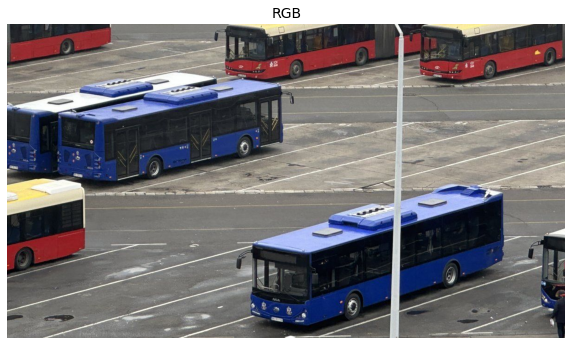

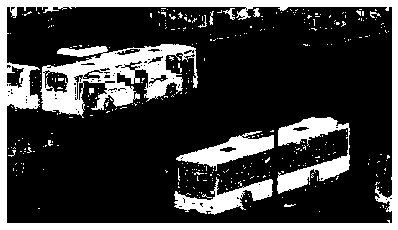

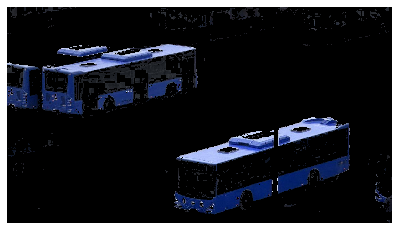

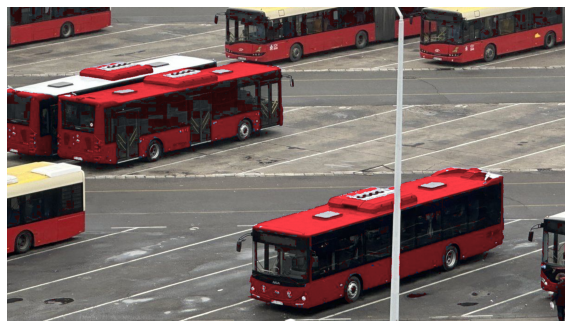

In [5]:
#ISTI POSTUPAK KORISCEN I U DRUGE DVE SLIKE, SAMO SE MASKE RAZLIKUJU

#Ucitavanje RGB slike
img_gsp2 = ski.io.imread(data_dir + "gsp2.jpg")

plt.figure(figsize=(10,10))
plt.imshow(img_gsp2)
plt.axis('off')
plt.title("RGB", fontsize=14)
plt.show()

#Iz RGB u HSV kolor sistem
img_hsv2 = ski.color.rgb2hsv(img_gsp2)


#------------------------------------

#Pravljenje maske gde sam pokusao da sa ogranicavanjem sve tri komponente HSV kolor sistema napravim sto bolju masku

mask2 = ((img_hsv2[:,:,0] < 0.74) & (img_hsv2[:,:,0] > 0.6)) & (img_hsv2[:,:,1] > 0.12) & (img_hsv2[:,:,2] > 0.12) 

ski.io.imshow(mask2, cmap = 'gray')
plt.axis('off')

img_masked2 = img_gsp2.copy()

#Kreirana maska se prosiruje na sve tri ravni kako bi se maskirala slika u boji
rgb_mask2 = np.stack((mask2, mask2, mask2), -1)

#Delovi koji nisu detektovani kao crvene oblasti se postavljaju na 0
img_masked2[~rgb_mask2] = 0

plt.figure();
ski.io.imshow(img_masked2);
plt.axis('off')

#-------------------------------

#Promena H komponente boje

img_hsv_out2 = img_hsv2.copy()
img_hsv_out2[:,:,0][mask2] = 0.992
img_hsv_out2[:,:,1][mask2] = 0.76

#Vracanje u RGB kolor sistem i prikaz rezultata

img_rgb_out2 = ski.color.hsv2rgb(img_hsv_out2)
plt.figure(figsize=(10, 10))
plt.imshow(img_rgb_out2)
plt.axis('off')

#Čuvanje izlazne slike u fajl
ski.io.imsave('gsp2Chagned.png', ski.util.img_as_ubyte(img_rgb_out2))


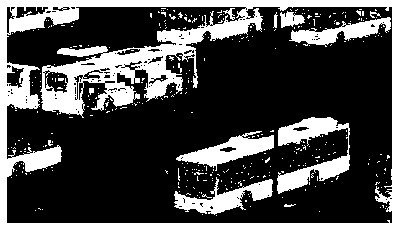

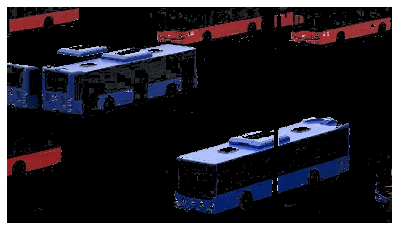

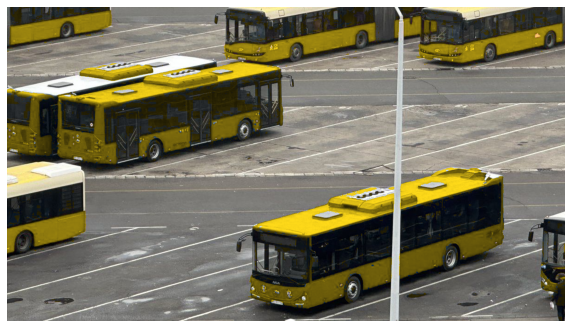

In [6]:
#Spajanje dve maske tako da se obuhvate svi autobusi

mask2_1 =mask2 | ((img_hsv2[:,:,0] < 0.06) | (img_hsv2[:,:,0] > 0.945)) & (img_hsv2[:,:,1] > 0.15) 

ski.io.imshow(mask2_1, cmap = 'gray')
plt.axis('off')

img_masked2_1 = img_gsp2.copy()

#Kreirana maska se prosiruje na sve tri ravni kako bi se maskirala slika u boji
rgb_mask2_1 = np.stack((mask2_1, mask2_1, mask2_1), -1)

#Delovi koji nisu detektovani kao crvene oblasti se postavljaju na 0
img_masked2_1[~rgb_mask2_1] = 0

plt.figure();
ski.io.imshow(img_masked2_1);
plt.axis('off')

#Promena H i V komponente boje na predefinisane vrednosti tako da su za sve tri izlazne slike autobusi iste boje

img_hsv_out2_1 = img_hsv2.copy()
img_hsv_out2_1[:,:,0][mask2_1] = 0.14
img_hsv_out2_1[:,:,1][mask2_1] = 0.9

img_rgb_out2_1 = ski.color.hsv2rgb(img_hsv_out2_1)
plt.figure(figsize=(10, 10))
plt.imshow(img_rgb_out2_1)
plt.axis('off')

#Cuvanje izlazne slike u fajl
ski.io.imsave('gsp2_1Chagned.png', ski.util.img_as_ubyte(img_rgb_out2_1))


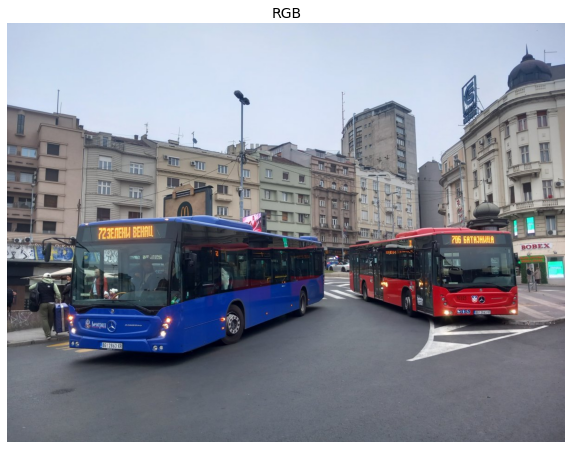

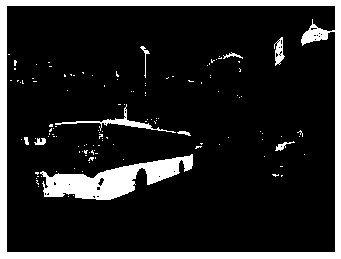

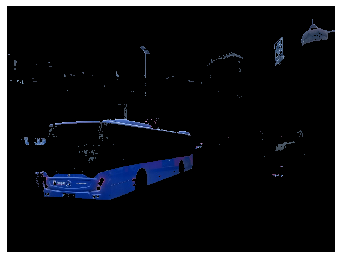

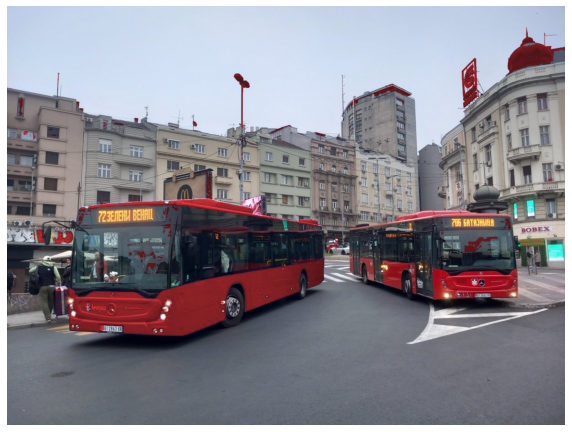

In [7]:
#PONAVLJAMO POSTUPAK I ZA TRECU SLIKU
#Ucitavanje slike
img_gsp3 = ski.io.imread(data_dir + "gsp3.jpg")

plt.figure(figsize=(10,10))
plt.imshow(img_gsp3)
plt.axis('off')
plt.title("RGB", fontsize=14)
plt.show()

#Konverzija u HSV kolor sistem
img_hsv3 = ski.color.rgb2hsv(img_gsp3)


#--------------------------------

#Pravljenje maske gde sam opet koristio sve tri komponente HSV kolor sistema za dobijanje boljeg rezultata
mask3 = ((img_hsv3[:,:,0] < 0.89) & (img_hsv3[:,:,0] > 0.58)) & (img_hsv3[:,:,1] > 0.25) & (img_hsv3[:,:,2] > 0.3) 

ski.io.imshow(mask3, cmap = 'gray')
plt.axis('off')


img_masked3 = img_gsp3.copy()

#Kreirana maska se prosiruje na sve tri ravni kako bi se maskirala slika u boji
rgb_mask3 = np.stack((mask3, mask3, mask3), -1)

#Delovi koji nisu detektovani kao crvene oblasti se postavljaju na 0
img_masked3[~rgb_mask3] = 0

plt.figure();
ski.io.imshow(img_masked3);
plt.axis('off')

#-----------------------------------------

#Promena H komponente boje

img_hsv_out3 = img_hsv3.copy()
img_hsv_out3[:,:,0][mask3] = 0.992
img_hsv_out3[:,:,1][mask3] = 0.76

#Konverzija nazad u RGB kolor sistem
img_rgb_out3 = ski.color.hsv2rgb(img_hsv_out3)
plt.figure(figsize=(10, 10))
plt.imshow(img_rgb_out3)
plt.axis('off')

#Cuvanje izlazne slike u fajl
ski.io.imsave('gsp3Chagned.png', ski.util.img_as_ubyte(img_rgb_out2))

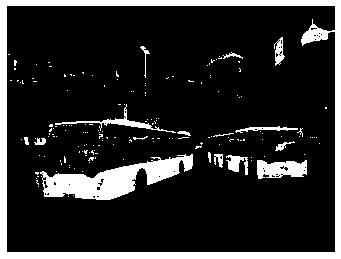

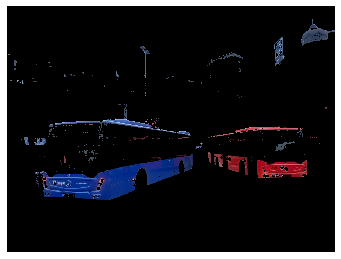

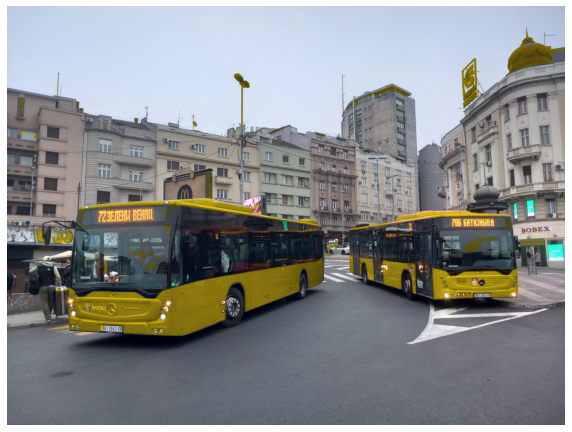

In [8]:
#Spajanjem maski obuhvatamo oba autobusa

mask3_1 = mask3 | ((img_hsv3[:,:,0] < 0.04) | (img_hsv3[:,:,0] > 0.95)) & (img_hsv3[:,:,1] > 0.35) 

ski.io.imshow(mask3_1, cmap = 'gray')
plt.axis('off')

img_masked3_1 = img_gsp3.copy()

#Kreirana maska se prosiruje na sve tri ravni kako bi se maskirala slika u boji
rgb_mask3_1 = np.stack((mask3_1, mask3_1, mask3_1), -1)

#Delovi koji nisu detektovani kao crvene oblasti se postavljaju na 0
img_masked3_1[~rgb_mask3_1] = 0

plt.figure();
ski.io.imshow(img_masked3_1);
plt.axis('off')

#Promena H i V komponente boje 

img_hsv_out3_1 = img_hsv3.copy()
img_hsv_out3_1[:,:,0][mask3_1] = 0.14
img_hsv_out3_1[:,:,1][mask3_1] = 0.9


img_rgb_out3_1 = ski.color.hsv2rgb(img_hsv_out3_1)
plt.figure(figsize=(10, 10))
plt.imshow(img_rgb_out3_1)
plt.axis('off')

#Cuvanje izlazne slike u fajl
ski.io.imsave('gsp3_1Chagned.png', ski.util.img_as_ubyte(img_rgb_out3_1))


DRUGI ZADATAK

U ovom delu zadatku ispitivan je uticaj izbora gornje granice intenziteta pri linearnoj normalizaciji HDR slike na konacni vizuelni rezultat. Kao ulaz koriscena je HDR slika, dok je jedini promenljivi parametar bio percentil koriscen za određivanje maksimalne vrednosti intenziteta (high_in). Testirane su sledece vrednosti:p = 99.9, p = 98.5, p = 98.0.

Cilj je bio da se ispita kako promena percentila utice na kontrast, zasicenje svetlih delova i vidljivost detalja u slici.
HDR slike sadrze piksele sa izuzetno velikim intenzitetima, koji mogu negativno uticati na kontrast ako se koristi apsolutni maksimum. Zbog toga je umesto maksimalne vrednosti koriscen percentil distribucije intenziteta, cime se ekstremne vrednosti zanemaruju.

Kod najveće vrednosti percentila zadrzan je gotovo kompletan dinamicki opseg slike. Svetli delovi (npr. refleksije na vodi i nebu) su ocuvani, ali je kontrast u srednjim i tamnim tonovima relativno slab. Smanjenjem percentila dolazi do jaceg odbacivanja ekstremno svetlih piksela. Time se povecava kontrast u srednjim tonovima, a detalji u vodi i obalnim delovima postaju izrazeniji. Svetli delovi pocinju blago da se zasicuju, ali bez znacajnog gubitka informacija. Daljim smanjenjem percentila znacajan deo svetlih piksela biva zasicen. Slika ima vrlo jak kontrast, ali se gube detalji u svetlim oblastima (nebo, refleksije). Tamni i srednji tonovi su naglaseni, ali rezultat deluje manje prirodno.

Pokazano je da izbor percentila ima kljucnu ulogu u procesu tone mapping-a HDR slike. Promenom samo jednog parametra moguce je znacajno promeniti vizuelni karakter rezultata. Pravilnim izborom percentila moze se postici balans između kontrasta i ocuvanja informacija, pri cemu optimalna vrednost zavisi od konkretne primene i subjektivnih kriterijuma kvaliteta slike.


/tmp/ipykernel_1136563/2693010880.py:12: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  f = f/np.max(f.flatten())
/tmp/ipykernel_1136563/2693010880.py:34: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  g_gamma = g ** gamma  # gama korekcija


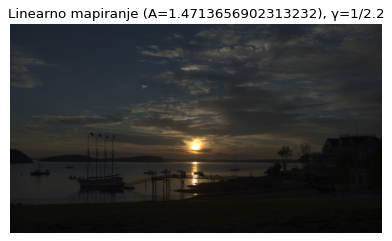

In [9]:
# Ucitavanje HDR slike

# Slika je u HDR formatu (floating point vrednosti)
# sto znaci da intenziteti piksela nisu ograničeni na [0, 255]
# vec mogu imati znatno siri dinamicki opseg

f = imageio.v2.imread(data_dir + 'sea.hdr', format='HDR-FI')

#Normalizacija slike
# Svi intenziteti se dele maksimalnom vrednoscu u slici čime se slika dovodi u opseg [0, 1]

f = f/np.max(f.flatten())

# Odredjivanje gornje granice intenziteta
# Umesto koriscenja apsolutnog maksimuma uzima se 99.9-ti procenat vrednosti intenziteta
# Na ovaj nacin se izbegava dominacija retkih ekstremno svetlih piksela koji bi degradirali kontrast slike

p = 99.9
high_in = np.percentile(f.flatten(), p)

# Linearno preslikavanje intenziteta
# Intenziteti iz opsega [0, high_in] se preslikavaju u opseg [0, 1]
# Sve vrednosti iznad high_in se zasicuju (clip), cime se povecava kontrast u vizuelno relevantnom delu slike

img_out = exposure.rescale_intensity(f, in_range=(0, high_in), out_range=(0,1))

# Parametri kontrasta i gama korekcije
# Parametar A predstavlja faktor kontrasta i zavisi od izabrane gornje granice intenziteta
# Gama korekcija (γ = 1/2.2) se koristi kako bi se prilagodila nelinearna percepcija ljudskog oka i karakteristike standardnih displeja.

A = 1/high_in   # kontrast
gamma = 1 / 2.2       
g = np.clip(img_out, 0, 1)  # ogranicenje opsega
g_gamma = g ** gamma  # gama korekcija

#Prikaz rezultata
plt.figure(figsize=(6,6), dpi = 80)
plt.imshow(g_gamma, cmap='gray', vmin=0, vmax=1)
plt.title(f'Linearno mapiranje (A={A}), γ=1/2.2')
plt.axis('off')
plt.show()


/tmp/ipykernel_1136563/4080978002.py:9: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  g_gamma = g ** gamma  # gama korekcija


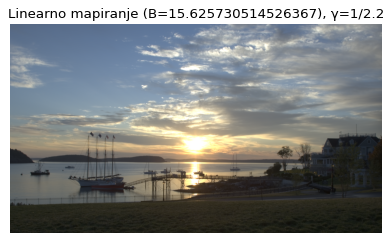

In [10]:
p = 98.5
high_in = np.percentile(f.flatten(), p)

img_out = exposure.rescale_intensity(f, in_range=(0, high_in), out_range=(0,1))

B = 1/high_in   # kontrast
gamma = 1 / 2.2       
g = np.clip(img_out, 0, 1)  # ogranicenje opsega
g_gamma = g ** gamma  # gama korekcija
plt.figure(figsize=(6,6), dpi = 80)
plt.imshow(g_gamma, cmap='gray', vmin=0, vmax=1)
plt.title(f'Linearno mapiranje (B={B}), γ=1/2.2')
plt.axis('off')
plt.show()


/tmp/ipykernel_1136563/2523582747.py:9: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  g_gamma = g ** gamma  # gama korekcija


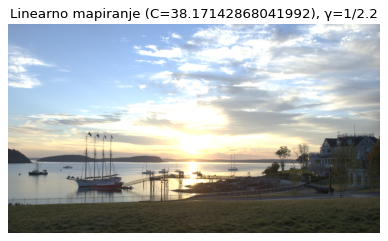

In [11]:
p = 88
high_in = np.percentile(f.flatten(), p)

img_out = exposure.rescale_intensity(f, in_range=(0, high_in), out_range=(0,1))

C = 1/high_in   # kontrast
gamma = 1 / 2.2       
g = np.clip(img_out, 0, 1)  # ogranicenje opsega
g_gamma = g ** gamma  # gama korekcija

plt.figure(figsize=(6,6), dpi = 80)
plt.imshow(g_gamma, cmap='gray', vmin=0, vmax=1)
plt.title(f'Linearno mapiranje (C={C}), γ=1/2.2')
plt.axis('off')
plt.show()


Vrednosti parametra c odredjene su eksperimentalno pomocu interact funkcije. 

Za c = 1.8
Kompresija dinamickog opsega je blaga. Svetli delovi su dobro ocuvani, ali tamni regioni ostaju slabije vidljivi.

Za c = 3.2
Predstavlja dobar kompromis između ocuvanja svetlih delova i isticanja detalja u senkama. Kontrast u srednjim tonovima je poboljsan, a slika deluje prirodnije.

Za c = 6
Dolazi do snazne kompresije svetlih vrednosti. Detalji u tamnim delovima postaju vrlo izrazeni, ali svetli delovi gube kontrast.

Povecanjem parametra c povecava se stepen kompresije dinamickog opsega. Prevelike vrednosti dovode do gubitka kontrasta u svetlim oblastima, dok premale vrednosti ne uspevaju da dovoljno istaknu detalje u senkama. U ovom delu zadatka, c=3.2 se pokazao kao izbor koji nam najvise odgovara.

In [12]:
'''

Preko interact opcije dolazim do odgovarajuce vrednosti parametra c

def log_transform(f, axes, c):
    g = log(1 + (10**c)*f)/log(1+10**c)
    plt.figure(figsize=(32,20)); axis('off')
    imshow(g)
    
    
interact(log_transform, f=fixed(f), axes=fixed(axes), c=(0,10,0.1))

'''

"\n\nPreko interact opcije dolazim do odgovarajuce vrednosti parametra c\n\ndef log_transform(f, axes, c):\n    g = log(1 + (10**c)*f)/log(1+10**c)\n    plt.figure(figsize=(32,20)); axis('off')\n    imshow(g)\n    \n    \ninteract(log_transform, f=fixed(f), axes=fixed(axes), c=(0,10,0.1))\n\n"

/tmp/ipykernel_1136563/2671982016.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  g1 = log(1 + (10**c1)*f)/log(1+10**c1)
/tmp/ipykernel_1136563/2671982016.py:5: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  g2 = log(1 + (10**c2)*f)/log(1+10**c2)
/tmp/ipykernel_1136563/2671982016.py:6: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  g3 = log(1 + (10**c3)*f)/log(1+10**c3)


(np.float64(-0.5), np.float64(1919.5), np.float64(1079.5), np.float64(-0.5))

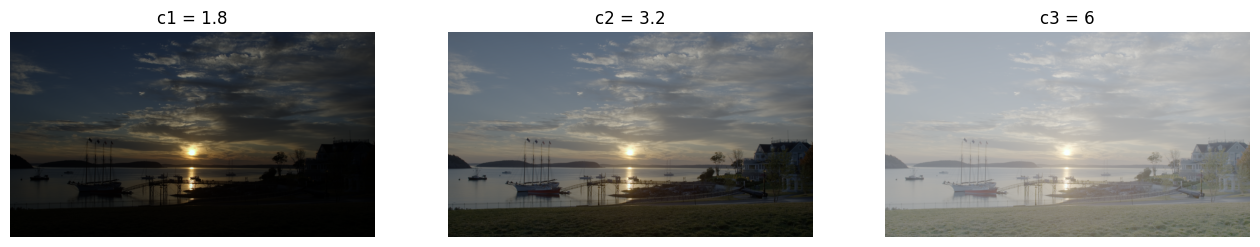

In [13]:
c1 = 1.8
c2 = 3.2
c3 = 6
g1 = log(1 + (10**c1)*f)/log(1+10**c1)
g2 = log(1 + (10**c2)*f)/log(1+10**c2)
g3 = log(1 + (10**c3)*f)/log(1+10**c3)

g1 = np.clip(g1, 0, 1)
g2 = np.clip(g2, 0, 1)
g3 = np.clip(g3, 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(16,8), dpi=100)
ax = axes.ravel()

ax[0].imshow(g1); ax[0].set_title('c1 = 1.8'); ax[0].axis('off')
ax[1].imshow(g2, cmap='gray'); ax[1].set_title('c2 = 3.2'); ax[1].axis('off')
ax[2].imshow(g3); ax[2].set_title('c3 = 6'); ax[2].axis('off')

I ove vrednosti su inicijalno određene koriscenjem interact funkcije.

b = 0.1
Izuzetno agresivno posvetljivanje. Veliki deo slike prelazi u veoma svetle tonove, uz gubitak kontrasta i detalja.

b = 0.3
Jasno poboljsanje vidljivosti tamnih oblasti uz zadrzavanje osnovne strukture slike. Kontrast je umeren.

b = 0.5
Najprirodniji rezultat medju testiranim vrednostima. Detalji su jasno vidljivi i u tamnim i u srednjim tonovima, uz dobar balans kontrasta.

Smanjenjem parametra b pojacava se uticaj posvetljivanja, ali previse male vrednosti dovode do degradacije slike. U ovom slucaju, b = 0.5 daje najbolji kompromis izmedju vidljivosti detalja i ocuvanja kontrasta.

In [14]:
'''
def gamma_transform(f, axes, b=0.5):
    h= f**b
    plt.figure(figsize=(32,20)); axis('off')
    imshow(h)
    
    
interact(gamma_transform, f=fixed(f), axes=fixed(axes), b=(0,1,0.02))
'''

"\ndef gamma_transform(f, axes, b=0.5):\n    h= f**b\n    plt.figure(figsize=(32,20)); axis('off')\n    imshow(h)\n    \n    \ninteract(gamma_transform, f=fixed(f), axes=fixed(axes), b=(0,1,0.02))\n"

/tmp/ipykernel_1136563/3723025664.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  h1 = f**b1
/tmp/ipykernel_1136563/3723025664.py:5: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  h2 = f**b2
/tmp/ipykernel_1136563/3723025664.py:6: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  h3 = f**b3


(np.float64(-0.5), np.float64(1919.5), np.float64(1079.5), np.float64(-0.5))

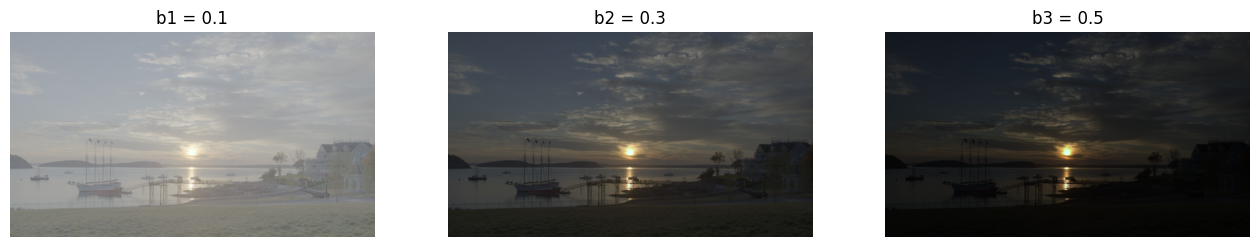

In [15]:
b1 = 0.1
b2 = 0.3
b3 = 0.5
h1 = f**b1
h2 = f**b2
h3 = f**b3

h1 = np.clip(h1, 0, 1)
h2 = np.clip(h2, 0, 1)
h3 = np.clip(h3, 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(16,8), dpi=100)
ax = axes.ravel()

ax[0].imshow(h1); ax[0].set_title('b1 = 0.1'); ax[0].axis('off')
ax[1].imshow(h2, cmap='gray'); ax[1].set_title('b2 = 0.3'); ax[1].axis('off')
ax[2].imshow(h3); ax[2].set_title('b3 = 0.5'); ax[2].axis('off')


Logaritamska transformacija je pogodnija za veoma sirok dinamicki opseg jer jace kompresuje ekstremne vrednosti.

Stepena transformacija je jednostavnija i pogodna za finu kontrolu kontrasta, ali moze biti pregruba za HDR sadrzaj.

TRECI ZADATAK

Za resavanje ovog zadatka cilj je bio poboljsanje ostrine slike isticanjem ivica i finih detalja, bez narusavanja prirodnog izgleda boja. Koriscen je YUV kolor sistem. Ovaj izbor je napravljen jer Y kanal nosi informaciju o luminansi, odnosno svetlini slike, dok U i V kanali sadrze informacije o boji. Na ovaj nacin je omoguceno da se izostravanje primeni samo na komponentu svetline, dok se kolor informacije zadrzavaju nepromenjene.

Za isticanje ivica koriscen je Laplasijan operator. Laplasijan filter naglasava nagle promene intenziteta, odnosno ivice i fine strukture, ali istovremeno moze pojacati i sum. Iz tog razloga Laplasijan nije koriscen direktno kao izlaz, vec kao komponenta koja se oduzima od originalne luminantne slike. 

Parametar alpha uveden je kao faktor kojim se kontrolise jacina izostravanja. Manje vrednosti alpha daju suptilno poboljsanje detalja, dok vece vrednosti dovode do agresivnog izostravanja koje moze rezultovati pojacavanjem suma. Vrednost alpha = 0.9 odabrana je eksperimentalno, jer daje jasno vidljivo poboljsanje ostrine. Povecanjem ovog parametra iznad izabrane vrednosti dolazi do degradacije kvaliteta slike, dok se njegovim smanjenjem efekat izostravanja znacajno umanjuje.

Nakon obrade Y kanala, rekonstruisana je YUV slika kombinovanjem izostrene luminanse sa originalnim hrominantnim komponentama. Slika je zatim vracena u RGB kolor prostor radi prikaza i cuvanja. Ogranicavanje intenziteta piksela na opseg [0,1] primenjeno je kako bi se osiguralo da dobijena slika ostane u validnom dinamickom opsegu.

Rezultati pokazuju da primena Laplasijan izostravanja u YUV prostoru omogucava efikasno poboljsanje vizuelne ostrine slike uz ocuvanje prirodnih boja. 

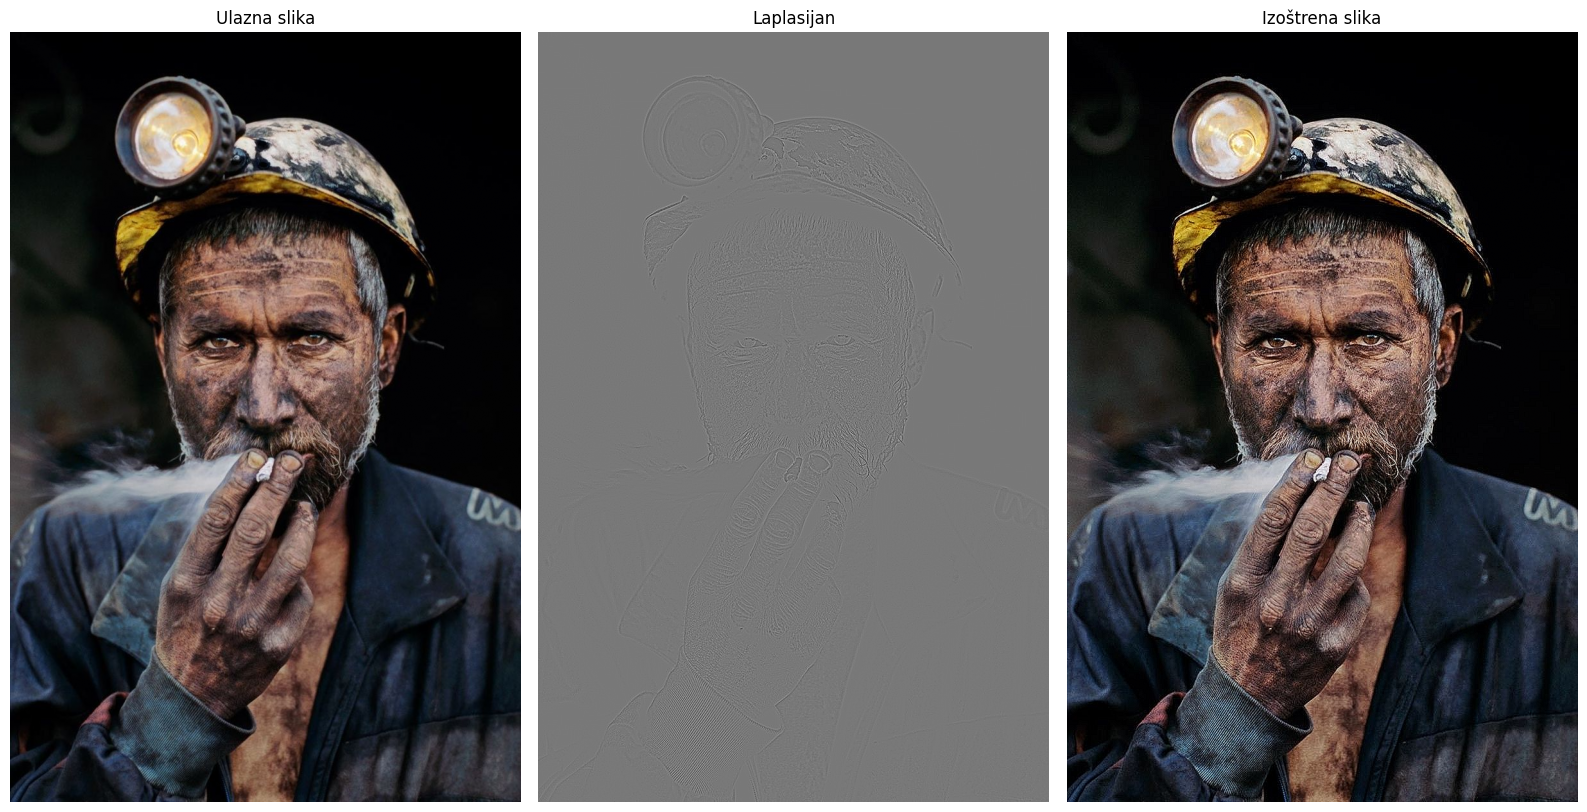

In [16]:
# Ulazna slika se ucitava i konvertuje u float tip sa opsegom [0, 1]
img_miner = util.img_as_float(io.imread(data_dir + 'miner.jpg'))

# RGB slika se konvertuje u YUV kolor prostor
# Izostravanje se vrsi iskljucivo na Y kanalu,  jer ljudsko oko najviše reaguje na promene osvetljenosti 


img_yuv = color.rgb2yuv(img_miner)
img_y = img_yuv[:,:,0]

# Pravljenje Laplasijan maske

laplacian_mask = np.array([[0,  1, 0],
                           [1, -4, 1],
                           [0,  1, 0]])

# Primenjen Laplasijan filtar

img_lap = ndimage.correlate(img_y, laplacian_mask)

# Izostravanje i clip-ovanje

alpha = 0.9
img_y_sharp = img_y - alpha * img_lap
img_y_sharp = np.clip(img_y_sharp, 0, 1)

# Rekontrukcija Yuv slike

img_yuv_out = np.zeros(img_yuv.shape)
img_yuv_out[:,:,1:3] = img_yuv[:,:,1:3]
img_yuv_out[:,:,0] = img_y_sharp

# Slika se konvertuje nazad u RGB prostor radi prikaza i čuvanja
# Ponovno ograničavanje vrednosti obezbeđuje validan intenzitet piksela

img_rgb_out = color.yuv2rgb(img_yuv_out)
img_rgb_out = np.clip(img_rgb_out, 0, 1)

# Prikaz rezultata

fig, axes = plt.subplots(1, 3, figsize=(16,8), dpi=100)
ax = axes.ravel()

ax[0].imshow(img_miner); ax[0].set_title('Ulazna slika'); ax[0].axis('off')
ax[1].imshow(img_lap, cmap='gray'); ax[1].set_title('Laplasijan'); ax[1].axis('off')
ax[2].imshow(img_rgb_out); ax[2].set_title('Izoštrena slika'); ax[2].axis('off')

plt.tight_layout()

#Cuvanje slike resenja

ski.io.imsave('miner_sharp.jpg', ski.util.img_as_ubyte(img_rgb_out))

CETVRTI ZADATAK

In [17]:
def dosCLAHE(imgIn, *args):

    if imgIn.dtype != np.uint8:
        raise ValueError("Ulazna slika mora biti tipa uint8")

    if imgIn.ndim not in [2, 3]:
        raise ValueError("Ulazna slika mora biti 2D ili 3D")

    if imgIn.ndim == 3 and imgIn.shape[2] != 3:
        raise ValueError("RGB slika mora imati 3 kanala")

    # parametri
    if len(args) == 0:
        numTiles = [8, 8]
        limit = 0.01
    elif len(args) == 1:
        numTiles = args[0]
        limit = 0.01
    elif len(args) == 2:
        numTiles = args[0]
        limit = args[1]
    else:
        raise ValueError("Previše argumenata")

    # luminansa
    if imgIn.ndim == 3:
        img_yuv = color.rgb2yuv(imgIn)
        img_Y = (img_yuv[:, :, 0] * 255).astype(np.uint8)
    else:
        img_Y = imgIn.copy()

    H, W = img_Y.shape

    # padding
    pad_h = (numTiles[0] - H % numTiles[0]) % numTiles[0]
    pad_w = (numTiles[1] - W % numTiles[1]) % numTiles[1]

    img_pad = np.pad(
        img_Y,
        ((0, pad_h), (0, pad_w)),
        mode='edge'
    )

    H_pad, W_pad = img_pad.shape
    tile_h = H_pad // numTiles[0]
    tile_w = W_pad // numTiles[1]

    # LUT za svaki blok
    luts = np.zeros((numTiles[0], numTiles[1], 256), dtype=np.uint8)

    #  RAČUNANJE LUT-OVA 
    for i in range(numTiles[0]):
        for j in range(numTiles[1]):

            r0 = i * tile_h
            r1 = (i + 1) * tile_h
            c0 = j * tile_w
            c1 = (j + 1) * tile_w

            block = img_pad[r0:r1, c0:c1]
            bh, bw = block.shape

            # histogram
            hist = np.zeros(256, dtype=np.int32)
            for r in range(bh):
                for c in range(bw):
                    hist[block[r, c]] += 1

            # clipping
            max_per_bin = max(1, int(limit * bh * bw))
            excess = 0
            for k in range(256):
                if hist[k] > max_per_bin:
                    excess += hist[k] - max_per_bin
                    hist[k] = max_per_bin

            hist += excess // 256

            # CDF
            cdf = np.cumsum(hist)
            cdf_min = cdf[cdf > 0][0]
            num_pixels = bh * bw

            # LUT
            for k in range(256):
                luts[i, j, k] = np.clip(
                    (cdf[k] - cdf_min) * 255 / (num_pixels - cdf_min),
                    0, 255
                )

    #  BILINEARNA INTERPOLACIJA 
    img_out = np.zeros_like(img_pad)

    for r in range(H_pad):
        for c in range(W_pad):

            ti = r // tile_h
            tj = c // tile_w

            ti = min(ti, numTiles[0] - 1)
            tj = min(tj, numTiles[1] - 1)

            ti1 = min(ti + 1, numTiles[0] - 1)
            tj1 = min(tj + 1, numTiles[1] - 1)

            dy = (r - ti * tile_h) / tile_h
            dx = (c - tj * tile_w) / tile_w

            val = img_pad[r, c]

            v00 = luts[ti , tj , val]
            v01 = luts[ti , tj1, val]
            v10 = luts[ti1, tj , val]
            v11 = luts[ti1, tj1, val]

            img_out[r, c] = (
                (1-dy)*(1-dx)*v00 +
                (1-dy)*dx*v01 +
                dy*(1-dx)*v10 +
                dy*dx*v11
            )

    # uklanjanje padding-a
    img_out = img_out[:H, :W]

    # nazad u RGB ako treba
    if imgIn.ndim == 3:
        img_yuv[:, :, 0] = img_out / 255.0
        img_out = (color.yuv2rgb(img_yuv) * 255).astype(np.uint8)

    return img_out

U ovom zadatku realizovana je adaptivna ekvalizacija histograma sa ogranicenjem kontrasta (CLAHE) sa ciljem poboljsanja lokalnog kontrasta slike. Slika je podeljena na vise manjih blokova, pri cemu je za svaki blok posebno racunata ekvalizacija histograma uz ogranicenje kontrasta kako ne bi doslo do pojacavanja suma.

Obrada je izvrsena nad Y kanalom u YUV kolor sistemu, cime je omoguceno poboljsanje kontrasta bez promene informacija o boji. Kako bi se izbegli nagli prelazi izmedju susednih blokova, primenjena je bilinearna interpolacija izmedju rezultata okolnih blokova.

Na osnovu dobijenih rezultata moze se zakljuciti da CLAHE daje bolje vizuelne rezultate u odnosu na globalnu ekvalizaciju, posebno u delovima slike sa slabijim kontrastom. Veci broj blokova omogucava precizniju lokalnu obradu, ali povecava vreme izvrsavanja, dok parametar ogranicenja kontrasta ima znacajan uticaj na jacinu efekta. 

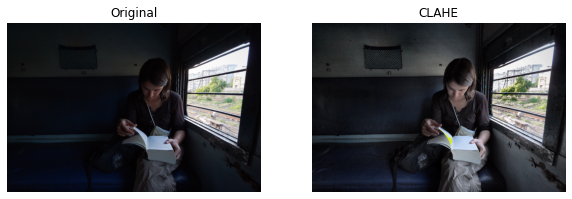

In [18]:
img_train = io.imread(data_dir + 'train.jpg')

img_clahe = dosCLAHE(img_train, [8, 8], 0.01)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img_train, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_clahe, cmap='gray')
plt.title('CLAHE')
plt.axis('off')
ski.io.imsave('train_bilinear.jpg', ski.util.img_as_ubyte(img_clahe))

dosCLAHE | blocks=1, limit=0, time=4.213 s
dosCLAHE | blocks=1, limit=0.01, time=4.875 s
dosCLAHE | blocks=1, limit=0.1, time=4.33 s
dosCLAHE | blocks=1, limit=1, time=3.909 s
dosCLAHE | blocks=4, limit=0, time=4.021 s
dosCLAHE | blocks=4, limit=0.01, time=3.923 s
dosCLAHE | blocks=4, limit=0.1, time=3.898 s
dosCLAHE | blocks=4, limit=1, time=3.961 s
dosCLAHE | blocks=8, limit=0, time=4.137 s
dosCLAHE | blocks=8, limit=0.01, time=4.083 s
dosCLAHE | blocks=8, limit=0.1, time=4.312 s
dosCLAHE | blocks=8, limit=1, time=3.873 s
dosCLAHE | blocks=16, limit=0, time=4.307 s
dosCLAHE | blocks=16, limit=0.01, time=4.239 s
dosCLAHE | blocks=16, limit=0.1, time=4.367 s
dosCLAHE | blocks=16, limit=1, time=4.277 s


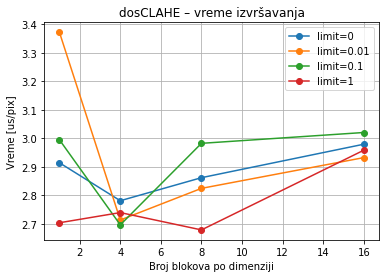

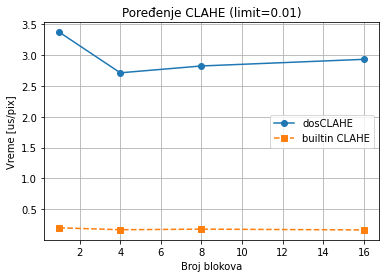

In [19]:
blocks = [1, 4, 8, 16]
limits = [0, 0.01, 0.1, 1]

times = np.zeros((len(blocks), len(limits)))
times_norm = np.zeros_like(times)

for i, b in enumerate(blocks):
    for j, lim in enumerate(limits):

        start = time.time()
        out = dosCLAHE(img_train, [b, b], lim)
        end = time.time()

        t = end - start
        times[i, j] = t
        times_norm[i, j] = t / img_train.size

        print(f"dosCLAHE | blocks={b}, limit={lim}, time={round(t,3)} s")
        
times_builtin = np.zeros_like(times)
times_builtin_norm = np.zeros_like(times)

for i, b in enumerate(blocks):
    for j, lim in enumerate(limits):

        start = time.time()
        _ = exposure.equalize_adapthist(
            img_train,
            kernel_size=(img_train.shape[0]//b, img_train.shape[1]//b),
            clip_limit=lim
        )
        end = time.time()

        t = end - start
        times_builtin[i, j] = t
        times_builtin_norm[i, j] = t / img_train.size
        
plt.figure()
for j, lim in enumerate(limits):
    plt.plot(blocks, times_norm[:, j]*1e6, marker='o', label=f'limit={lim}')

plt.xlabel("Broj blokova po dimenziji")
plt.ylabel("Vreme [us/pix]")
plt.title("dosCLAHE – vreme izvršavanja")
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.plot(blocks, times_norm[:,1]*1e6, 'o-', label='dosCLAHE')
plt.plot(blocks, times_builtin_norm[:,1]*1e6, 's--', label='builtin CLAHE')

plt.xlabel("Broj blokova")
plt.ylabel("Vreme [us/pix]")
plt.title("Poređenje CLAHE (limit=0.01)")
plt.legend()
plt.grid(True)
plt.show()